# ECBM gốc trên CUB, seed 2026

> **Bản thêm seed (13/11/2026).** Giống hệt notebook `ecbm-cub` (seed 42): cùng code gốc, dữ liệu, 100 epoch, SGD 0.01, batch 64, FP16. **Chỉ khác:** `random_seed = 2026`; tắt chấm test (`main.py` tự chấm sau khi train, và mục 13–14) trừ khi `EVALUATE_TEST = True`; phần chạy thử dùng ảnh validation thay cho ảnh test. Checkpoint `last.ckpt` của notebook này là Input cho `ga-ecbm-cub-seed2026`.

**Cài đặt Kaggle:** Accelerator **GPU T4 x2**, Internet **On**, rồi **Save Version → Save & Run All**. Khoảng 4.5 giờ.

**Dữ liệu.** Gồm ảnh `CUB_200_2011` và bộ chia tập + concept đã xử lý `CUB_processed/class_attr_data_10` của CBM (Koh et al., 2020). Cả hai tải từ CodaLab của CBM, đúng nguồn mà README của ECBM chỉ tới. 112 concept đã được bỏ phiếu đa số theo loài, nên mọi ảnh cùng loài có chung một vector concept. Mục 7 kiểm tra lại điều này.

## 1. Cấu hình

In [1]:
# ===== 1. Cấu hình =====
import os, sys, re, json, time, shutil, pickle, tarfile, subprocess
from pathlib import Path

EPOCHS = 100   # như seed 42; bài gốc train 300 epoch (configs/cub.json)
SEED = 2026     # seed 42 đã chạy ở notebook ecbm-cub
EVALUATE_TEST = False   # chỉ bật khi đã đồng ý chấm tập test
os.environ["ECBM_RUN_TEST"] = "1" if EVALUATE_TEST else "0"   # main.py chỉ tự chấm test khi = 1

OFFICIAL_REPO = "https://github.com/xmed-lab/ECBM.git"
OFFICIAL_COMMIT = "d38c43aeb22a44465aa5344af5a3b7bad72211ae"   # commit duy nhất hiện có của repo
# Dữ liệu trên CodaLab của CBM (Koh et al., 2020)
CUB_IMAGES_URL = "https://worksheets.codalab.org/rest/bundles/0xd013a7ba2e88481bbc07e787f73109f5/contents/blob/"     # CUB_200_2011, ~1.3 GB
CUB_PROCESSED_URL = "https://worksheets.codalab.org/rest/bundles/0x5b9d528d2101418b87212db92fea6683/contents/blob/"  # CUB_processed, ~9 MB

WORK = Path(os.environ.get("ECBM_WORK", "/kaggle/working"))   # Kaggle lưu thư mục này vào tab Output
INPUT = Path(os.environ.get("ECBM_INPUT", "/kaggle/input"))    # dataset gắn thêm, nếu có
DATA = Path(os.environ.get("ECBM_DATA", "/tmp/cub_data"))      # dữ liệu tạm, không đưa vào Output
REPO = WORK / "ECBM"
OUT = WORK / "ecbm_cub_results"
for folder in (WORK, OUT, DATA):
    folder.mkdir(parents=True, exist_ok=True)

# Bảng 1 của bài (5 seed): (trung bình, độ lệch chuẩn)
PAPER = {"concept_accuracy": (0.973, 0.001),
         "overall_concept_accuracy": (0.713, 0.009),
         "class_accuracy": (0.812, 0.006)}

NOTEBOOK_START = time.time()
print("Kết quả sẽ lưu ở", OUT)

Kết quả sẽ lưu ở /kaggle/working/ecbm_cub_results


## 2. Hàm tiện ích

Các hàm dùng chung: chạy lệnh, sửa file cấu hình JSON của tác giả, đọc log và đọc chỉ số TensorBoard.

In [2]:
# ===== 2. Hàm tiện ích =====
def run(cmd, cwd=None, env=None, check=True, show=True):
    """Chạy một lệnh, in phần cuối kết quả; dừng notebook nếu lệnh lỗi."""
    cmd = [str(part) for part in cmd]
    print("$", " ".join(cmd))
    result = subprocess.run(cmd, cwd=cwd, env=env, text=True, capture_output=True)
    output = (result.stdout or "") + (result.stderr or "")
    if (show or result.returncode) and output.strip():
        print(output[-4000:])
    if check and result.returncode:
        raise RuntimeError(f"Lệnh lỗi (mã {result.returncode}): {' '.join(cmd)}")
    return result


def run_logged(cmd, log_path, env, every_sec=600, status=None):
    """Chạy lệnh dài trong thư mục code gốc, ghi toàn bộ log ra file; cứ every_sec giây in một dòng tiến độ."""
    start = last = time.time()
    with open(log_path, "w") as log:
        process = subprocess.Popen([str(part) for part in cmd], cwd=REPO, env=env,
                                   stdout=log, stderr=subprocess.STDOUT, text=True)
        while process.poll() is None:
            time.sleep(min(15, every_sec))
            if time.time() - last >= every_sec:
                last = time.time()
                try:
                    message = status() if status else "đang chạy…"
                except Exception as error:   # file log/TensorBoard đang được ghi dở
                    message = f"chưa đọc được tiến độ ({type(error).__name__})"
                print(f"[{(last - start) / 60:6.1f} phút] {message}", flush=True)
    print(Path(log_path).read_text(errors="replace")[-3000:])
    if process.returncode:
        raise RuntimeError(f"Lệnh lỗi (mã {process.returncode}); log đầy đủ ở {log_path}")
    return time.time() - start


def edit_json(path, **updates):
    """Sửa giá trị vài khóa trong file cấu hình JSON của tác giả, chỉ đụng đúng dòng đó để git diff gọn."""
    path = Path(path)
    text = path.read_text()
    old_config = json.loads(text)
    for key, value in updates.items():
        pattern = rf'("{re.escape(key)}"\s*:\s*)([^,\n]+)'
        if len(re.findall(pattern, text)) != 1:
            raise RuntimeError(f"Không thấy đúng một khóa {key} trong {path.name}")
        text = re.sub(pattern, lambda match: match.group(1) + json.dumps(value), text)
        print(f"  {path.name}: {key}: {old_config.get(key)!r} → {value!r}")
    new_config = json.loads(text)
    assert all(new_config[key] == value for key, value in updates.items())
    path.write_text(text)


def replace_once(path, old, new):
    """Thay đúng một chỗ trong file của tác giả; báo lỗi nếu không thấy để không sửa nhầm."""
    path = Path(path)
    text = path.read_text()
    if text.count(old) != 1:
        raise RuntimeError(f"Không thấy đúng một chỗ cần sửa trong {path.name}. Hãy chạy lại mục 4 trước.")
    path.write_text(text.replace(old, new))
    print(f"  đã sửa {path.relative_to(REPO)}")


def link(target, source):
    """Tạo symlink target → source, thay symlink cũ nếu có."""
    target = Path(target)
    if target.is_symlink():
        target.unlink()
    target.symlink_to(Path(source))


def experiment_dirs():
    """Các thư mục kết quả mà script của tác giả tạo trong ECBM/exp/."""
    root = REPO / "exp"
    return {path for path in root.iterdir() if path.is_dir()} if root.exists() else set()


def newest(folders):
    return max(folders, key=lambda path: path.stat().st_mtime)


def read_log_metrics(log_file, names):
    """Lấy giá trị cuối của từng chỉ số trong log.txt của tác giả ('ten-0.81' hoặc 'ten: tensor(0.81)')."""
    text = Path(log_file).read_text(errors="replace")
    values = {}
    for name in names:
        found = re.findall(rf"^{re.escape(name)}(?:-|: )(?:tensor\()?([-+0-9.eE]+)", text, flags=re.M)
        values[name] = float(found[-1]) if found else None
    return values


def ecbm_env(data_dir):
    """Biến môi trường cho các script của tác giả."""
    env = os.environ.copy()
    env.update(CUB_DATA_DIR=str(data_dir),          # data/data_util.py đọc biến này sau khi sửa ở mục 8
               CUBLAS_WORKSPACE_CONFIG=":4096:8",   # để cuBLAS chạy tất định như tác giả muốn
               PYTHONUNBUFFERED="1")
    return env


def tensorboard_scalars(run_dir):
    """Đọc chỉ số pytorch-lightning ghi vào TensorBoard: {tên: [giá trị theo thứ tự bước]}."""
    from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
    series = {}
    for file in sorted(Path(run_dir).rglob("events.out.tfevents.*")):
        accumulator = EventAccumulator(str(file), size_guidance={"scalars": 0})
        accumulator.Reload()
        for tag in accumulator.Tags()["scalars"]:
            series.setdefault(tag, []).extend((event.step, event.wall_time, event.value)
                                              for event in accumulator.Scalars(tag))
    return {tag: [value for *_, value in sorted(points)] for tag, points in series.items()}


def save_state(**values):
    """Ghi tiến trình vào state.json để các mục sau đọc lại được kể cả khi kernel khởi động lại."""
    state_file = OUT / "state.json"
    state = json.loads(state_file.read_text()) if state_file.exists() else {}
    state.update({key: str(value) if isinstance(value, Path) else value for key, value in values.items()})
    state_file.write_text(json.dumps(state, indent=2, ensure_ascii=False))
    return state


def load_state():
    return json.loads((OUT / "state.json").read_text())

## 3. Kiểm tra GPU

In [3]:
# ===== 3. Kiểm tra GPU =====
import torch, numpy
print(f"Python {sys.version.split()[0]} | torch {torch.__version__} (CUDA {torch.version.cuda}) | numpy {numpy.__version__}")
if not torch.cuda.is_available():
    raise SystemExit("Chưa có GPU: Settings → Accelerator → GPU T4 x2, rồi chạy lại từ đầu.")
for index in range(torch.cuda.device_count()):
    props = torch.cuda.get_device_properties(index)
    print(f"GPU {index}: {props.name} (sm_{props.major}{props.minor}), {props.total_memory / 2**30:.1f} GB")
print("PyTorch này hỗ trợ:", torch.cuda.get_arch_list())
try:   # thử một phép tính thật: P100 (sm_60) báo lỗi "no kernel image" với PyTorch mới
    (torch.ones(4, device="cuda") * 2).sum().item()
except RuntimeError as error:
    raise SystemExit(f"GPU này không chạy được với PyTorch của Kaggle ({error}). Chọn Accelerator → GPU T4 x2.")
if torch.cuda.device_count() > 1:
    print("Lưu ý: main.py của tác giả chỉ dùng GPU 0, GPU còn lại sẽ để trống.")
print(f"Ổ đĩa {WORK}: còn trống {shutil.disk_usage(WORK).free / 2**30:.0f} GB")

Python 3.13.16 | torch 2.11.0+cu130 (CUDA 13.0) | numpy 2.1.3
GPU 0: Tesla T4 (sm_75), 14.6 GB
GPU 1: Tesla T4 (sm_75), 14.6 GB
PyTorch này hỗ trợ: ['sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']
Lưu ý: main.py của tác giả chỉ dùng GPU 0, GPU còn lại sẽ để trống.
Ổ đĩa /kaggle/working: còn trống 20 GB


## 4. Tải code gốc của tác giả

Clone repo và chốt đúng commit `d38c43a`. Nếu chạy lại cell này, mọi chỗ đã sửa ở mục 8 bị xoá và code trở về đúng bản của tác giả.

In [4]:
# ===== 4. Tải code gốc =====
if not (REPO / ".git").exists():
    run(["git", "clone", "--quiet", OFFICIAL_REPO, REPO])
run(["git", "-C", REPO, "checkout", "--quiet", "--force", OFFICIAL_COMMIT])
run(["git", "-C", REPO, "log", "-1", "--format=commit %H%nngày   %ad%n%s"])

$ git clone --quiet https://github.com/xmed-lab/ECBM.git /kaggle/working/ECBM
$ git -C /kaggle/working/ECBM checkout --quiet --force d38c43aeb22a44465aa5344af5a3b7bad72211ae
$ git -C /kaggle/working/ECBM log -1 --format=commit %H%nngày   %ad%n%s
commit d38c43aeb22a44465aa5344af5a3b7bad72211ae
ngày   Thu May 1 17:38:59 2025 +0800
Add files via upload



CompletedProcess(args=['git', '-C', '/kaggle/working/ECBM', 'log', '-1', '--format=commit %H%nngày   %ad%n%s'], returncode=0, stdout='commit d38c43aeb22a44465aa5344af5a3b7bad72211ae\nngày   Thu May 1 17:38:59 2025 +0800\nAdd files via upload\n', stderr='')

## 5. Cài thư viện

`requirements.txt` của tác giả dùng **pytorch-lightning 1.6.4**. Code cần đúng bản 1.x vì dùng `Trainer.add_argparse_args` và `test_epoch_end`, hai thứ đã bị bỏ ở bản 2.x.
- pip từ bản 24.1 trở đi từ chối metadata cũ của gói này, nên phải hạ pip trong phiên này rồi cài không kèm phụ thuộc.
- Giữ nguyên torch/numpy của Kaggle. Bản numpy 1.24 trong `requirements.txt` không hợp với torch mới, nên không cài theo.
- Phần khác biệt của NumPy 2 được xử lý ở mục 8.

In [5]:
# ===== 5. Cài thư viện =====
pip = [sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check"]
run(pip + ["pip<24.1"])                                   # pip ≥ 24.1 từ chối metadata của PL 1.6.4
run(pip + ["--no-deps", "pytorch-lightning==1.6.4"])      # đúng bản trong requirements.txt của tác giả
run(pip + ["pyDeprecate==0.3.2", "torchmetrics==0.9.3"])  # phụ thuộc hợp với PL 1.6.4
if run([sys.executable, "-c", "import pkg_resources"], check=False, show=False).returncode:
    run(pip + ["setuptools<81"])                          # PL 1.6.4 và torchmetrics 0.9.3 còn dùng pkg_resources
for module, package in {"fsspec": "fsspec", "yaml": "pyyaml", "tqdm": "tqdm", "tensorboard": "tensorboard",
                        "sklearn": "scikit-learn", "pandas": "pandas", "matplotlib": "matplotlib"}.items():
    if run([sys.executable, "-c", f"import {module}"], check=False, show=False).returncode:
        run(pip + [package])

probe = ("import json, sys, torch, torchvision, numpy, sklearn, pytorch_lightning, torchmetrics; "
         "print(json.dumps({'python': sys.version.split()[0], 'torch': torch.__version__, "
         "'torchvision': torchvision.__version__, 'numpy': numpy.__version__, 'scikit-learn': sklearn.__version__, "
         "'pytorch-lightning': pytorch_lightning.__version__, 'torchmetrics': torchmetrics.__version__}))")
VERSIONS = json.loads(run([sys.executable, "-W", "ignore", "-c", probe], show=False).stdout.strip().splitlines()[-1])
print(json.dumps(VERSIONS, indent=2))
assert VERSIONS["pytorch-lightning"] == "1.6.4"
save_state(versions=VERSIONS)

$ /usr/bin/python3 -m pip install -q --disable-pip-version-check pip<24.1
$ /usr/bin/python3 -m pip install -q --disable-pip-version-check --no-deps pytorch-lightning==1.6.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 585.5/585.5 kB 6.3 MB/s eta 0:00:00

$ /usr/bin/python3 -m pip install -q --disable-pip-version-check pyDeprecate==0.3.2 torchmetrics==0.9.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.6/419.6 kB 8.9 MB/s eta 0:00:00
DEPRECATION: pytorch-lightning 1.6.4 has a non-standard dependency specifier torch>=1.8.*. pip 24.1 will enforce this behaviour change. A possible replacement is to upgrade to a newer version of pytorch-lightning or contact the author to suggest that they release a version with a conforming dependency specifiers. Discussion can be found at https://github.com/pypa/pip/issues/12063
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pyt

{'versions': {'python': '3.13.16',
  'torch': '2.11.0+cu130',
  'torchvision': '0.26.0+cu130',
  'numpy': '2.1.3',
  'scikit-learn': '1.6.1',
  'pytorch-lightning': '1.6.4',
  'torchmetrics': '0.9.3'}}

## 6. Tải dữ liệu CUB

Cell này tìm dữ liệu trong dataset đã gắn ở `/kaggle/input` trước; nếu không có mới tải từ CodaLab vào `/tmp`. Ảnh nặng khoảng 1.3 GB.

In [6]:
# ===== 6. Tải dữ liệu CUB =====
def find_first(pattern):
    """Tìm trong dataset đã gắn (/kaggle/input) trước, rồi trong thư mục tạm."""
    for root in (INPUT, DATA):
        if root.exists():
            for hit in root.rglob(pattern):
                return hit
    return None


def download(url, name):
    """Tải một bundle CodaLab (.tar.gz) rồi giải nén vào DATA/name."""
    target, archive = DATA / name, DATA / f"{name}.tar.gz"
    for attempt in range(1, 4):
        if run(["curl", "-L", "--fail", "-sS", "--retry", "3", "-o", archive, url], check=False).returncode == 0:
            break
        print(f"Tải lỗi lần {attempt}, thử lại sau 30 giây")
        time.sleep(30)
    else:
        raise RuntimeError(f"Không tải được {url}")
    print(f"Đã tải {archive.stat().st_size / 2**20:.0f} MB, đang giải nén…")
    shutil.rmtree(target, ignore_errors=True)
    with tarfile.open(archive) as tar:
        try:
            tar.extractall(target, filter="data")
        except TypeError:   # Python cũ chưa có tham số filter
            tar.extractall(target)
    archive.unlink()


start = time.time()
if find_first("class_attr_data_10/train.pkl") is None:
    download(CUB_PROCESSED_URL, "CUB_processed")
PROCESSED_DIR = find_first("class_attr_data_10/train.pkl").parent

if find_first("images/001.Black_footed_Albatross") is None:
    download(CUB_IMAGES_URL, "CUB_200_2011")
IMAGES_DIR = find_first("images/001.Black_footed_Albatross").parent

print("Chia tập + concept:", PROCESSED_DIR)
print("Ảnh:", IMAGES_DIR, f"({sum(1 for _ in IMAGES_DIR.rglob('*.jpg'))} file .jpg)")
print(f"Xong sau {(time.time() - start) / 60:.1f} phút")

$ curl -L --fail -sS --retry 3 -o /tmp/cub_data/CUB_processed.tar.gz https://worksheets.codalab.org/rest/bundles/0x5b9d528d2101418b87212db92fea6683/contents/blob/
Đã tải 9 MB, đang giải nén…
Chia tập + concept: /tmp/cub_data/CUB_processed/class_attr_data_10
Ảnh: /kaggle/input/datasets/wenewone/cub2002011/CUB_200_2011/images (11796 file .jpg)
Xong sau 0.5 phút


## 7. Kiểm tra dữ liệu và xếp đúng chỗ code gốc đọc

Code gốc đọc `CUB_DATA_DIR/{train,val,test}.pkl` và ảnh ở `CUB_DATA_DIR/images/...`. Cell này tạo thư mục đó bằng symlink, rồi kiểm tra:
- số ảnh của từng tập;
- mỗi ảnh có đủ 112 concept;
- mỗi loài chỉ có một vector concept, và vector đó khớp file `cub_mapping.json` của tác giả;
- không thiếu file ảnh nào.

In [7]:
# ===== 7. Kiểm tra dữ liệu =====
EXPECTED_COUNTS = {"train": 4796, "val": 1198, "test": 5794}   # cách chia của CBM

CUB_FULL = DATA / "cub_full"
CUB_FULL.mkdir(parents=True, exist_ok=True)
for split in EXPECTED_COUNTS:
    link(CUB_FULL / f"{split}.pkl", PROCESSED_DIR / f"{split}.pkl")
link(CUB_FULL / "images", IMAGES_DIR)


def image_file(record, root):
    """Giống CUBDataset.__getitem__: bỏ phần đường dẫn trước 'CUB_200_2011' rồi nối vào thư mục dữ liệu."""
    parts = record["img_path"].split("/")
    return Path(root, *parts[parts.index("CUB_200_2011") + 1:])


class_to_concepts = json.loads((REPO / "cub_mapping.json").read_text())   # 200 loài × 112 concept
SPLITS = {}
for split, expected in EXPECTED_COUNTS.items():
    with open(CUB_FULL / f"{split}.pkl", "rb") as handle:
        records = pickle.load(handle)
    SPLITS[split] = records
    vectors = {}
    for record in records:
        vectors.setdefault(record["class_label"], set()).add(tuple(int(v) for v in record["attribute_label"]))
    lengths = {len(record["attribute_label"]) for record in records}
    mixed = sum(len(v) > 1 for v in vectors.values())
    matches = all(list(next(iter(v))) == class_to_concepts[k] for k, v in vectors.items())
    missing = sum(not image_file(record, CUB_FULL).exists() for record in records)
    positives = sum(sum(int(v) for v in record["attribute_label"]) for record in records) / len(records)
    print(f"{split:5s}: {len(records):5d} ảnh | {len(vectors):3d} loài | {sorted(lengths)} concept/ảnh | "
          f"trung bình {positives:.1f} concept 'có' | loài có >1 vector: {mixed} | "
          f"khớp cub_mapping.json: {matches} | thiếu ảnh: {missing}")
    assert len(records) == expected, f"{split}: cần {expected} ảnh"
    assert lengths == {112} and mixed == 0 and matches and missing == 0
print("Dữ liệu đúng như cách CBM xử lý: concept gán theo loài, mỗi loài đúng một vector 112 chiều.")

train:  4796 ảnh | 200 loài | [112] concept/ảnh | trung bình 22.9 concept 'có' | loài có >1 vector: 0 | khớp cub_mapping.json: True | thiếu ảnh: 0
val  :  1198 ảnh | 200 loài | [112] concept/ảnh | trung bình 23.0 concept 'có' | loài có >1 vector: 0 | khớp cub_mapping.json: True | thiếu ảnh: 0
test :  5794 ảnh | 200 loài | [112] concept/ảnh | trung bình 23.0 concept 'có' | loài có >1 vector: 0 | khớp cub_mapping.json: True | thiếu ảnh: 0
Dữ liệu đúng như cách CBM xử lý: concept gán theo loài, mỗi loài đúng một vector 112 chiều.


## 8. Sửa tối thiểu để chạy được trên Kaggle

| File | Sửa gì | Vì sao |
|---|---|---|
| `data/data_util.py` | Đường dẫn CUB lấy từ biến môi trường `CUB_DATA_DIR` | Code gốc ghi cứng đường dẫn trên máy tác giả |
| `main.py` | `use_deterministic_algorithms(True)` → thêm `warn_only=True` | Trên GPU, backward của AdaptiveAvgPool2d (trong ResNet) không có bản tất định nên có thể dừng với lỗi. cuBLAS vẫn được giữ tất định bằng biến `CUBLAS_WORKSPACE_CONFIG` |
| `configs/cub.json` | `epochs` 300 → 100; `enable_progress_bar` → false | Chạy thử; tắt thanh tiến độ chỉ để log gọn, không đổi phép tính |
| `configs/cub_inference.json` | `trained_weight` → checkpoint cuối (làm ở mục 13) | README hướng dẫn điền đường dẫn này |

Ngoài ra, mọi script của tác giả được chạy qua `compat_run.py`. File này thêm lại `np.Inf` và `np.NaN`, hai tên NumPy 2 đã bỏ nhưng `utils.py` của tác giả và pytorch-lightning 1.6.4 vẫn dùng, rồi chạy nguyên file gốc.

In [8]:
# ===== 8. Sửa tối thiểu =====
replace_once(REPO / "data/data_util.py",
             'CUB_DATA_DIR = "/home/xxucb/data/pcbm_dataset/CUB"',
             'CUB_DATA_DIR = os.environ.get("CUB_DATA_DIR", "/home/xxucb/data/pcbm_dataset/CUB")')
replace_once(REPO / "main.py",
             "torch.use_deterministic_algorithms(True)",
             "torch.use_deterministic_algorithms(True, warn_only=True)")
edit_json(REPO / "configs/cub.json", epochs=EPOCHS, enable_progress_bar=False, random_seed=SEED)
replace_once(REPO / "main.py", "    trainer.test(model=model,ckpt_path=None,dataloaders=test_loader)",
             "    if os.environ.get('ECBM_RUN_TEST') == '1':\n        trainer.test(model=model,ckpt_path=None,dataloaders=test_loader)")

LAUNCHER = WORK / "compat_run.py"
LAUNCHER.write_text("""# Chạy nguyên một script của tác giả sau khi thêm lại np.Inf, np.NaN (NumPy 2 đã bỏ).
# utils.py của tác giả và ModelCheckpoint của pytorch-lightning 1.6.4 còn dùng np.Inf.
import os
import runpy
import sys

import numpy as np

for old_name, value in (("Inf", np.inf), ("NaN", np.nan)):
    if not hasattr(np, old_name):
        setattr(np, old_name, value)

script = sys.argv[1]
sys.argv = sys.argv[1:]
sys.path.insert(0, os.getcwd())
runpy.run_path(script, run_name="__main__")
""")

diff = run(["git", "-C", REPO, "diff"], show=False).stdout
(OUT / "patches.diff").write_text(diff)
print(diff)

  đã sửa data/data_util.py
  đã sửa main.py
  cub.json: epochs: 300 → 100
  cub.json: enable_progress_bar: True → False
  cub.json: random_seed: 42 → 2026
  đã sửa main.py
$ git -C /kaggle/working/ECBM diff
diff --git a/configs/cub.json b/configs/cub.json
index c038937..2b0a697 100644
--- a/configs/cub.json
+++ b/configs/cub.json
@@ -1,5 +1,5 @@
 {
-  "random_seed": 42,
+  "random_seed": 2026,
   "dataset": "cub",
   "freezebb": false,
   "gpu": 0,
@@ -22,7 +22,7 @@
   "sweep": false,
   "optim": "sgd",
   "learning_rate": 0.01,
-  "epochs": 300,
+  "epochs": 100,
   "batch_size": 64,
   "lr_c":1e-1,
   "lr_y":1e-1,
@@ -46,7 +46,7 @@
   "ipus": null,
   "log_gpu_memory": null,
   "progress_bar_refresh_rate": null,
-  "enable_progress_bar": true,
+  "enable_progress_bar": false,
   "overfit_batches": 0.0,
   "track_grad_norm": -1,
   "check_val_every_n_epoch": 1,
diff --git a/data/data_util.py b/data/data_util.py
index 5dc7c90..1fa6cf4 100644
--- a/data/data_util.py
+++ b/data/data_util

## 9. Đo bộ nhớ GPU và tốc độ

Chạy vài bước train của chính mô hình và hàm loss của tác giả, với batch 64 và ảnh 299×299 trên dữ liệu ngẫu nhiên. Các cấu hình được thử theo thứ tự:
1. **FP32, batch 64:** đúng như tác giả.
2. **Mixed precision (AMP), batch 64:** nếu FP32 hết bộ nhớ.
3. **FP32, batch 32, cộng dồn 2 bước:** nếu AMP cũng hết bộ nhớ.

Cấu hình nào khác tác giả sẽ được ghi vào `summary.json`.

In [9]:
# ===== 9. Đo bộ nhớ GPU và tốc độ =====
BENCH_BATCH, BENCH_STEPS = 64, 10
(WORK / "bench_step.py").write_text(r"""# Một bước train của ECBM tác giả (ResNet101, ảnh 299, 112 concept, 200 loài) trên dữ liệu ngẫu nhiên.
# In ra JSON: bộ nhớ GPU cao nhất và số giây mỗi bước.
import json
import sys
import time
from argparse import Namespace

import torch

from loss import EBMLoss_concept, EBMLoss_label
from networks.EBM import ECBM

precision, batch, steps = (int(value) for value in sys.argv[1:4])
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
model = ECBM(Namespace(cy_perturb_prob=0.2, cy_permute_prob=0.2, freezebb=False),
             emb_size=2048, cpt_size=112, hid_size=512, n_classes=200).to(device).train()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=4e-5)
label_loss = EBMLoss_label(list(range(200)), device)
concept_loss = EBMLoss_concept(list(range(112)), device)
use_amp = precision == 16
scaler = (torch.amp.GradScaler("cuda", enabled=use_amp) if hasattr(torch.amp, "GradScaler")
          else torch.cuda.amp.GradScaler(enabled=use_amp))
images = torch.randn(batch, 3, 299, 299, device=device)
concepts = torch.randint(0, 2, (batch, 112), device=device)
labels = torch.randint(0, 200, (batch,), device=device)


def train_step():
    optimizer.zero_grad(set_to_none=True)
    with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
        out_xy, out_cy, out_c = model(images, concepts, True)
        loss = 3 * label_loss(out_xy, labels) + concept_loss(out_c, concepts) + label_loss(out_cy, labels)
    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()


try:
    for _ in range(2):   # khởi động
        train_step()
    if device == "cuda":
        torch.cuda.synchronize()
    start = time.time()
    for _ in range(steps):
        train_step()
    if device == "cuda":
        torch.cuda.synchronize()
    peak = torch.cuda.max_memory_allocated() / 2**30 if device == "cuda" else None
    print(json.dumps({"ok": True, "precision": precision, "sec_per_step": (time.time() - start) / steps,
                      "peak_gb": peak}))
except RuntimeError as error:   # torch.cuda.OutOfMemoryError là lớp con của RuntimeError
    if "out of memory" not in str(error).lower():
        raise
    print(json.dumps({"ok": False, "precision": precision, "error": "out of memory"}))
""")

BENCH = None
for precision, batch, accumulate in [(32, BENCH_BATCH, 1), (16, BENCH_BATCH, 1), (32, BENCH_BATCH // 2, 2)]:
    result = run([sys.executable, LAUNCHER, WORK / "bench_step.py", precision, batch, BENCH_STEPS],
                 cwd=REPO, env=ecbm_env(CUB_FULL), check=False, show=False)
    lines = [line for line in result.stdout.splitlines() if line.startswith("{")]
    outcome = json.loads(lines[-1]) if lines else {"ok": False, "error": (result.stderr or "")[-1500:]}
    print(f"precision {precision}, batch {batch}, cộng dồn {accumulate} bước: {outcome}")
    if outcome.get("ok"):
        BENCH = dict(outcome, batch=batch, accumulate=accumulate)
        break
if BENCH is None:
    raise RuntimeError("Không cấu hình nào vừa bộ nhớ GPU")

TRAIN_OVERRIDES = {}
if BENCH["precision"] != 32:
    TRAIN_OVERRIDES["precision"] = BENCH["precision"]
if BENCH["accumulate"] != 1:
    TRAIN_OVERRIDES.update(batch_size=BENCH["batch"], accumulate_grad_batches=BENCH["accumulate"])
TRAIN_OVERRIDES["precision"] = 16   # cố định như seed 42 (ecbm-cub và ga-ecbm-cub đều chạy FP16)
print("Khác cấu hình tác giả:", TRAIN_OVERRIDES or "không, giữ nguyên FP32 và batch 64")

train_steps = EXPECTED_COUNTS["train"] // BENCH["batch"]      # drop_last=True như code gốc
val_steps = -(-EXPECTED_COUNTS["val"] // BENCH["batch"])      # chỉ forward, khoảng 1/3 thời gian một bước train
epoch_minutes = BENCH["sec_per_step"] * (train_steps + val_steps / 3) * 1.15 / 60   # +15% cho đọc ảnh, lưu checkpoint
print(f"Ước lượng: {epoch_minutes:.1f} phút/epoch → {EPOCHS} epoch ≈ {epoch_minutes * EPOCHS / 60:.1f} giờ")
if epoch_minutes * EPOCHS / 60 > 10.5:
    print("CẢNH BÁO: có thể vượt giới hạn 12 giờ/phiên của Kaggle. Hãy giảm EPOCHS ở mục 1.")
save_state(bench=BENCH, train_overrides=TRAIN_OVERRIDES)

$ /usr/bin/python3 /kaggle/working/compat_run.py /kaggle/working/bench_step.py 32 64 10
precision 32, batch 64, cộng dồn 1 bước: {'ok': False, 'precision': 32, 'error': 'out of memory'}
$ /usr/bin/python3 /kaggle/working/compat_run.py /kaggle/working/bench_step.py 16 64 10
precision 16, batch 64, cộng dồn 1 bước: {'ok': True, 'precision': 16, 'sec_per_step': 1.6468355894088744, 'peak_gb': 8.226274013519287}
Khác cấu hình tác giả: {'precision': 16}
Ước lượng: 2.5 phút/epoch → 100 epoch ≈ 4.2 giờ


{'versions': {'python': '3.13.16',
  'torch': '2.11.0+cu130',
  'torchvision': '0.26.0+cu130',
  'numpy': '2.1.3',
  'scikit-learn': '1.6.1',
  'pytorch-lightning': '1.6.4',
  'torchmetrics': '0.9.3'},
 'bench': {'ok': True,
  'precision': 16,
  'sec_per_step': 1.6468355894088744,
  'peak_gb': 8.226274013519287,
  'batch': 64,
  'accumulate': 1},
 'train_overrides': {'precision': 16}}

## 10. Chạy thử nhanh toàn bộ quy trình

Trước khi train vài giờ, cell này chạy nguyên `main.py` (1 epoch) và `GradientInference.py` trên 128/64/128 ảnh, để chắc toàn bộ quy trình không lỗi. Số ở bước này không có ý nghĩa; checkpoint chạy thử bị xoá ngay sau đó.

In [10]:
# ===== 10. Chạy thử nhanh =====
SMOKE_SIZES = {"train": 128, "val": 64, "test": 128}
CUB_SMOKE = DATA / "cub_smoke"
CUB_SMOKE.mkdir(parents=True, exist_ok=True)
for split, size in SMOKE_SIZES.items():
    with open(CUB_SMOKE / f"{split}.pkl", "wb") as handle:
        source = split if (split != "test" or EVALUATE_TEST) else "val"   # không đụng ảnh test
        pickle.dump(SPLITS[source][:size], handle)
link(CUB_SMOKE / "images", IMAGES_DIR)

train_config, inference_config = REPO / "configs/cub.json", REPO / "configs/cub_inference.json"
saved_train_config, saved_inference_config = train_config.read_text(), inference_config.read_text()
start = time.time()
try:
    edit_json(train_config, epochs=1, **TRAIN_OVERRIDES)
    before = experiment_dirs()
    run_logged([sys.executable, LAUNCHER, "main.py", "--dataset", "cub"], OUT / "smoke_train.log",
               ecbm_env(CUB_SMOKE), every_sec=120)
    smoke_train_dir = newest(experiment_dirs() - before)
    assert (smoke_train_dir / "last.ckpt").exists(), "main.py không lưu last.ckpt"
    print("main.py:", read_log_metrics(smoke_train_dir / "log.txt", ["accuracy_test_c", "accuracy_test_c_overall",
                                                                   "accuracy_test_y_xy", "accuracy_test_y_cy"]))

    edit_json(inference_config, trained_weight=str(smoke_train_dir / "last.ckpt"))
    before = experiment_dirs()
    run_logged([sys.executable, LAUNCHER, "GradientInference.py", "--dataset", "cub"], OUT / "smoke_inference.log",
               ecbm_env(CUB_SMOKE), every_sec=120)
    smoke_inference_dir = newest(experiment_dirs() - before)
    smoke_metrics = read_log_metrics(smoke_inference_dir / "log.txt",
                                     ["concept_accuracy", "concept_overall_accuracy", "y_accuracy"])
    print("GradientInference.py:", smoke_metrics)
    assert all(value is not None for value in smoke_metrics.values()), "Không đọc được kết quả suy luận"
finally:
    train_config.write_text(saved_train_config)        # trả cấu hình về như sau mục 8
    inference_config.write_text(saved_inference_config)

shutil.rmtree(smoke_train_dir)                         # checkpoint chạy thử ~600 MB mỗi file
shutil.rmtree(smoke_inference_dir)
print(f"Chạy thử thành công sau {(time.time() - start) / 60:.1f} phút. Số ở bước này không có ý nghĩa.")

  cub.json: epochs: 100 → 1
  cub.json: precision: 32 → 16
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/imports.py:22: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
I0000 00:00:1794564204.294037     177 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Global seed set to 2026
128 training set size
64 val set size
128 test set size
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/core/lightning.py:2067: DeprecationWarning: `torch.distributed._sharded_tensor` will be deprecated, use `torch.distributed._shard.sharded_tensor` instead
  from torch.distributed._sharded_tensor import pre_load_state_dict_hook, state_dict_hook
Using 16bit native Automatic Mixed Precision (AMP)
/usr/local/lib/python3.13/dist-packa

## 11. Train ECBM

Chạy `main.py` của tác giả trên toàn bộ tập train (4.796 ảnh), chọn checkpoint theo val loss như code gốc. Cứ 10 phút cell in một dòng tiến độ đọc từ TensorBoard; log đầy đủ ở `train_stdout.log`.

Sau khi train, `main.py` tự chấm tập test bằng cách đọc trực tiếp năng lượng. **Đó không phải cách suy luận của bài**; số dùng để so với bài lấy ở mục 13.

In [11]:
# ===== 11. Train ECBM =====
MONITOR_EVERY_SEC = 600
if TRAIN_OVERRIDES:
    edit_json(REPO / "configs/cub.json", **TRAIN_OVERRIDES)
train_settings = json.loads((REPO / "configs/cub.json").read_text())
print("Cấu hình train:", {key: train_settings.get(key) for key in
      ("epochs", "batch_size", "accumulate_grad_batches", "precision", "optim", "learning_rate", "momentum",
       "weight_decay", "lambda_xy", "lambda_xc", "lambda_cy", "random_seed", "backbone", "img_size")})

before = experiment_dirs()


def training_status():
    new = experiment_dirs() - before
    if not new:
        return "đang khởi động…"
    scalars = tensorboard_scalars(newest(new))
    done = len(scalars.get("epoch_val_loss", []))
    if not done:
        return "đang train epoch đầu…"
    last = lambda tag: scalars.get(tag, [float("nan")])[-1]
    return (f"xong {done}/{EPOCHS} epoch | val loss {last('epoch_val_loss'):.3f} | concept {last('accuracy_val_c'):.3f}"
            f" | overall concept {last('accuracy_val_c_overall'):.3f} | class x→y {last('accuracy_val_y_xy'):.3f}")


train_seconds = run_logged([sys.executable, LAUNCHER, "main.py", "--dataset", "cub"], OUT / "train_stdout.log",
                           ecbm_env(CUB_FULL), every_sec=MONITOR_EVERY_SEC, status=training_status)
TRAIN_DIR = newest(experiment_dirs() - before)
shutil.copy(TRAIN_DIR / "log.txt", OUT / "train_log.txt")
DIRECT_TEST = read_log_metrics(TRAIN_DIR / "log.txt", ["accuracy_test_c", "accuracy_test_c_overall",
                                                      "accuracy_test_y_xy", "accuracy_test_y_cy"])
save_state(train_dir=TRAIN_DIR, train_hours=train_seconds / 3600, direct_test=DIRECT_TEST)
print(f"Train xong sau {train_seconds / 3600:.2f} giờ. Checkpoint ở {TRAIN_DIR}")
print("Global seed trong log:", re.findall(r"Global seed set to \d+",
      (OUT / "train_stdout.log").read_text(errors="replace"))[-1:])
assert f"random_seed={SEED}" in (TRAIN_DIR / "log.txt").read_text(errors="replace"), "Seed không đúng"
if EVALUATE_TEST:
    print("main.py tự chấm test (đọc trực tiếp năng lượng, chưa phải số so với bài):", DIRECT_TEST)

  cub.json: precision: 32 → 16
Cấu hình train: {'epochs': 100, 'batch_size': 64, 'accumulate_grad_batches': None, 'precision': 16, 'optim': 'sgd', 'learning_rate': 0.01, 'momentum': 0.9, 'weight_decay': 4e-05, 'lambda_xy': 3, 'lambda_xc': 1, 'lambda_cy': 1, 'random_seed': 2026, 'backbone': 'resnet101_imagenet', 'img_size': 299}


I0000 00:00:1794564887.783043      23 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


[  10.0 phút] xong 3/100 epoch | val loss 57.757 | concept 0.797 | overall concept 0.000 | class x→y 0.016
[  20.1 phút] xong 7/100 epoch | val loss 49.822 | concept 0.832 | overall concept 0.002 | class x→y 0.048
[  30.1 phút] xong 11/100 epoch | val loss 44.276 | concept 0.847 | overall concept 0.003 | class x→y 0.303
[  40.1 phút] xong 16/100 epoch | val loss 42.680 | concept 0.856 | overall concept 0.003 | class x→y 0.467
[  50.1 phút] xong 20/100 epoch | val loss 39.466 | concept 0.871 | overall concept 0.016 | class x→y 0.523
[  60.1 phút] xong 24/100 epoch | val loss 34.389 | concept 0.894 | overall concept 0.063 | class x→y 0.660
[  70.1 phút] xong 28/100 epoch | val loss 34.359 | concept 0.896 | overall concept 0.104 | class x→y 0.652
[  80.1 phút] xong 32/100 epoch | val loss 34.152 | concept 0.900 | overall concept 0.143 | class x→y 0.662
[  90.1 phút] xong 36/100 epoch | val loss 32.184 | concept 0.910 | overall concept 0.216 | class x→y 0.708
[ 100.1 phút] xong 40/100 epoc

## 12. Biểu đồ học

Mỗi ô là một chỉ số theo epoch. Màu theo tập dữ liệu: xanh là train, cam là validation, xanh ngọc nét đứt là validation đọc nhãn qua nhánh concept→nhãn. Con số ở cuối mỗi đường là giá trị validation ở epoch cuối.

Ô *Loss*: code tác giả tính loss train có trọng số 3 : 1 : 1, còn loss validation cộng không trọng số. Vì vậy chỉ nên xem xu hướng của từng đường, không so mức của hai đường với nhau. Validation ở đây cũng đọc trực tiếp năng lượng, chưa phải suy luận gradient.

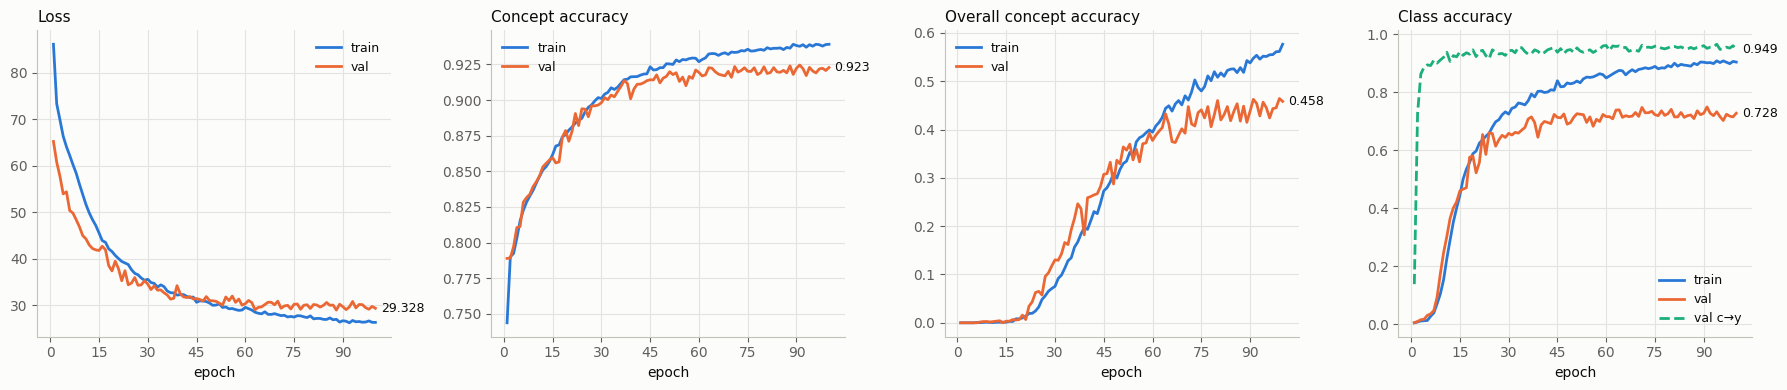

Validation ở epoch cuối: {'epoch_val_loss': 29.3277, 'epoch_val_loss_xy': 1.3072, 'epoch_val_loss_cy': 0.2011, 'epoch_val_loss_c': 27.8195, 'accuracy_val_c_overall': 0.4583, 'accuracy_val_c': 0.9229, 'accuracy_val_y_xy': 0.7279, 'accuracy_val_y_cy': 0.9491}


In [12]:
# ===== 12. Biểu đồ học =====
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

TRAIN_DIR = Path(load_state()["train_dir"])   # đọc lại để cell vẫn chạy được sau khi kernel khởi động lại
curves = tensorboard_scalars(TRAIN_DIR)

SERIES_STYLE = {   # màu theo tập dữ liệu, giữ nguyên ở mọi ô
    "train": dict(color="#2a78d6", linestyle="-"),
    "val": dict(color="#eb6834", linestyle="-"),
    "val c→y": dict(color="#1baf7a", linestyle="--"),
}
PANELS = [
    ("Loss", [("epoch_loss_epoch", "train"), ("epoch_val_loss", "val")]),
    ("Concept accuracy", [("accuracy_train_c", "train"), ("accuracy_val_c", "val")]),
    ("Overall concept accuracy", [("accuracy_train_c_overall", "train"), ("accuracy_val_c_overall", "val")]),
    ("Class accuracy", [("accuracy_train_y_xy", "train"), ("accuracy_val_y_xy", "val"), ("accuracy_val_y_cy", "val c→y")]),
]
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
                     "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b", "xtick.color": "#5f5e5a",
                     "ytick.color": "#5f5e5a", "font.size": 10})
fig, axes = plt.subplots(1, len(PANELS), figsize=(18, 4))
for ax, (title, series) in zip(axes, PANELS):
    for tag, label in series:
        values = curves.get(tag, [])
        if not values:
            continue
        epochs = range(1, len(values) + 1)
        ax.plot(epochs, values, linewidth=2, label=label, **SERIES_STYLE[label])
        if label != "train":   # chỉ ghi số ở cuối đường validation
            ax.annotate(f"{values[-1]:.3f}", (len(values), values[-1]), xytext=(4, 0),
                        textcoords="offset points", va="center", fontsize=9, color="#0b0b0b")
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("epoch")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(color="#e4e3df", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(OUT / "learning_curves.png", dpi=130)
plt.show()

final_table = {tag: round(values[-1], 4) for tag, values in curves.items()
               if tag.startswith(("accuracy_val", "epoch_val_loss"))}
print("Validation ở epoch cuối:", final_table)

## 13. Suy luận gradient trên tập test

Đây là cách suy luận của bài (Algorithm 1): giữ cố định mạng, tối ưu xác suất concept và nhãn để tổng năng lượng nhỏ nhất, với trọng số 1 : 1 : 0.01 (`configs/cub_inference.json`). Theo README, cell dùng **checkpoint cuối** (`last.ckpt`). Ba số ở cell này là số đem so với bài.

In [13]:
# ===== 13. Suy luận gradient trên tập test =====
if EVALUATE_TEST:
    TRAIN_DIR = Path(load_state()["train_dir"])
    inference_config = REPO / "configs/cub_inference.json"
    edit_json(inference_config, trained_weight=str(TRAIN_DIR / "last.ckpt"))
    n_batches = -(-EXPECTED_COUNTS["test"] // int(json.loads(inference_config.read_text())["batch_size"]))
    inference_log = OUT / "inference_stdout.log"


    def inference_status():
        done = inference_log.read_text(errors="replace").count("Before Intervention")
        return f"xong {done}/{n_batches} batch test"


    before = experiment_dirs()
    inference_seconds = run_logged([sys.executable, LAUNCHER, "GradientInference.py", "--dataset", "cub"], inference_log,
                                   ecbm_env(CUB_FULL), every_sec=300, status=inference_status)
    INFERENCE_DIR = newest(experiment_dirs() - before)
    shutil.copy(INFERENCE_DIR / "log.txt", OUT / "inference_log.txt")
    for name in ("y_pred.npy", "y_gt.npy", "c_pred.npy", "c_gt.npy"):   # dự đoán từng ảnh do tác giả lưu
        if (INFERENCE_DIR / name).exists():
            shutil.copy(INFERENCE_DIR / name, OUT / name)

    raw = read_log_metrics(INFERENCE_DIR / "log.txt", ["concept_accuracy", "concept_overall_accuracy", "y_accuracy"])
    RESULT = {"concept_accuracy": raw["concept_accuracy"],
              "overall_concept_accuracy": raw["concept_overall_accuracy"],
              "class_accuracy": raw["y_accuracy"]}
    save_state(inference_dir=INFERENCE_DIR, inference_minutes=inference_seconds / 60, result=RESULT)
    print(f"Suy luận xong sau {inference_seconds / 60:.1f} phút:", RESULT)
else:
    print('Bỏ qua mục 13: EVALUATE_TEST = False (không chấm test).')

Bỏ qua mục 13: EVALUATE_TEST = False (không chấm test).


## 14. So sánh với số trong bài

Cột cuối cho biết số chạy lại có nằm trong khoảng ±2 lần độ lệch chuẩn mà tác giả báo hay không. Lần này chỉ train 100 epoch thay vì 300, nên lệch một chút là có thể xảy ra.

In [14]:
# ===== 14. So sánh với số trong bài =====
if EVALUATE_TEST:
    import pandas as pd

    state = load_state()
    RESULT = state["result"]
    LABELS = {"concept_accuracy": "Concept accuracy",
              "overall_concept_accuracy": "Overall concept accuracy (đúng cả 112)",
              "class_accuracy": "Class accuracy"}
    rows = []
    for key, (mean, std) in PAPER.items():
        ours = RESULT[key]
        rows.append({"Chỉ số": LABELS[key],
                     "Bài (5 seed)": f"{mean:.3f} ± {std:.3f}",
                     f"Chạy lại ({EPOCHS} epoch, 1 seed)": round(ours, 4),
                     "Chênh": round(ours - mean, 4),
                     "Trong ±2 độ lệch chuẩn": abs(ours - mean) <= 2 * std})
    comparison = pd.DataFrame(rows)
    print(comparison.to_string(index=False))
    comparison.to_csv(OUT / "comparison.csv", index=False)

    summary = {
        "goal": "Tái lập ECBM (Xu et al., ICLR 2024) trên CUB bằng code chính thức",
        "code": {"repo": OFFICIAL_REPO, "commit": OFFICIAL_COMMIT, "patches": "patches.diff",
                 "launcher": "compat_run.py (thêm np.Inf, np.NaN cho NumPy 2)"},
        "differences_from_paper": {"epochs": EPOCHS, "seeds": 1,
                                   "config_overrides": state.get("train_overrides", {})},
        "gradient_inference_test": RESULT,
        "main_py_direct_test": state.get("direct_test"),
        "paper": {key: {"mean": mean, "std": std} for key, (mean, std) in PAPER.items()},
        "time": {"train_hours": state.get("train_hours"), "inference_minutes": state.get("inference_minutes"),
                 "notebook_hours": (time.time() - NOTEBOOK_START) / 3600},
        "versions": state.get("versions"),
        "benchmark": state.get("bench"),
    }
    (OUT / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False))
    print("\nĐã lưu", OUT / "summary.json")
    print("Các file trong Output:", sorted(path.name for path in OUT.iterdir()))
else:
    print('Bỏ qua mục 14: EVALUATE_TEST = False.')
    state = load_state()
    (OUT / "summary.json").write_text(json.dumps({
        "seed": SEED, "epochs": EPOCHS, "train_dir": state.get("train_dir"),
        "train_hours": state.get("train_hours"), "train_overrides": state.get("train_overrides"),
        "test_evaluated": False, "versions": state.get("versions")}, indent=2, ensure_ascii=False))
    print("Đã lưu", OUT / "summary.json")

Bỏ qua mục 14: EVALUATE_TEST = False.
Đã lưu /kaggle/working/ecbm_cub_results/summary.json


## Đọc kết quả và bước tiếp theo

- **Số để so với bài là mục 13**, lấy từ suy luận gradient. Số `main.py` tự chấm ở mục 11 đọc trực tiếp năng lượng, chỉ để tham khảo.
- **Nếu ba số nằm trong ±2 độ lệch chuẩn**, có thể nói đã tái lập được với 100 epoch. **Nếu lệch**, xem biểu đồ ở mục 12: nếu đường validation còn đang lên thì nên chạy đủ 300 epoch.
- **Chạy đủ 300 epoch:** đổi `EPOCHS = 300` ở mục 1. Nếu ước lượng ở mục 9 vượt khoảng 10 giờ thì phải chia thành hai phiên.
- **Các file trong tab Output**
  - `ecbm_cub_results/`: `summary.json`, `comparison.csv`, `learning_curves.png`, log, `patches.diff`, dự đoán từng ảnh.
  - `ECBM/exp/`: checkpoint, khoảng 600 MB mỗi file. Tác giả lưu 5 checkpoint tốt nhất theo val loss và `last.ckpt`.